# 02. Limpieza y transformación

In [2]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [3]:
df_bank = pd.read_csv("../data/raw/bank-additional.csv")

excel = pd.ExcelFile("../data/raw/customer-details.xlsx")
hojas = {nombre: pd.read_excel(excel, sheet_name=nombre) for nombre in excel.sheet_names}

In [4]:
df_clientes = pd.concat(hojas.values(), ignore_index=True)
df_clientes.shape

(43170, 7)

In [5]:
df_bank = df_bank.drop(columns="Unnamed: 0")
df_clientes = df_clientes.drop(columns="Unnamed: 0")

print(df_bank.shape, df_clientes.shape)

(43000, 23) (43170, 6)


In [6]:
renombrar_bank = {
    "age": "edad",
    "job": "trabajo",
    "marital": "estado_civil",
    "education": "educacion",
    "default": "impago",
    "housing": "hipoteca",
    "loan": "prestamo",
    "contact": "medio_contacto",
    "duration": "duracion",
    "campaign": "contactos_campana",
    "pdays": "dias_ultimo_contacto",
    "previous": "contactos_previos",
    "poutcome": "resultado_previo",
    "emp.var.rate": "tasa_var_empleo",
    "cons.price.idx": "indice_precios",
    "cons.conf.idx": "indice_confianza",
    "euribor3m": "euribor_3m",
    "nr.employed": "num_empleados",
    "y": "suscrito",
    "date": "fecha_contacto",
    "latitude": "latitud",
    "longitude": "longitud",
    "id_": "id_cliente",
}

renombrar_clientes = {
    "Income": "ingresos",
    "Kidhome": "num_ninos",
    "Teenhome": "num_adolescentes",
    "Dt_Customer": "fecha_alta",
    "NumWebVisitsMonth": "visitas_web_mes",
    "ID": "id_cliente",
}

df_bank = df_bank.rename(columns=renombrar_bank)
df_clientes = df_clientes.rename(columns=renombrar_clientes)

In [7]:
print(df_bank.columns.tolist())
print(df_clientes.columns.tolist())

['edad', 'trabajo', 'estado_civil', 'educacion', 'impago', 'hipoteca', 'prestamo', 'medio_contacto', 'duracion', 'contactos_campana', 'dias_ultimo_contacto', 'contactos_previos', 'resultado_previo', 'tasa_var_empleo', 'indice_precios', 'indice_confianza', 'euribor_3m', 'num_empleados', 'suscrito', 'fecha_contacto', 'latitud', 'longitud', 'id_cliente']
['ingresos', 'num_ninos', 'num_adolescentes', 'fecha_alta', 'visitas_web_mes', 'id_cliente']


In [8]:
columnas_coma = ["indice_precios", "indice_confianza", "euribor_3m", "num_empleados"]

for col in columnas_coma:
    df_bank[col] = pd.to_numeric(df_bank[col].str.replace(",", ".", regex=False))

In [9]:
df_bank[columnas_coma].dtypes

indice_precios      float64
indice_confianza    float64
euribor_3m          float64
num_empleados       float64
dtype: object

In [10]:
df_bank[columnas_coma].isnull().sum()

indice_precios       471
indice_confianza       0
euribor_3m          9256
num_empleados          0
dtype: int64

In [11]:
# BORRAR 

df_bank.sample(5)


,edad,trabajo,estado_civil,educacion,impago,hipoteca,prestamo,medio_contacto,duracion,contactos_campana,dias_ultimo_contacto,contactos_previos,resultado_previo,tasa_var_empleo,indice_precios,indice_confianza,euribor_3m,num_empleados,suscrito,fecha_contacto,latitud,longitud,id_cliente
18296,30.0,admin.,SINGLE,university.degree,0.0,1.0,0.0,cellular,27,3,999,0,NONEXISTENT,1.4,93.918,-42.7,NaN,5228.1,no,7-enero-2018,28.075,-87.021,d5321b85-2951-44d7-b7d3-f0e4438b39a9
34730,33.0,blue-collar,MARRIED,basic.6y,NaN,1.0,1.0,cellular,306,4,999,1,FAILURE,-1.8,92.893,-46.2,NaN,5099.1,no,24-julio-2018,40.787,-78.002,02714ca4-730c-4004-8ea7-8233a15c1fbc
10886,39.0,management,MARRIED,basic.9y,0.0,0.0,0.0,telephone,255,2,999,0,NONEXISTENT,1.4,94.465,-41.8,4.962,5228.1,no,11-enero-2019,37.753,-69.437,558811fc-95ae-4bd5-88af-b70b5d961f1a
3496,24.0,student,SINGLE,high.school,0.0,NaN,NaN,telephone,86,1,999,0,NONEXISTENT,1.1,93.994,-36.4,4.859,5191.0,no,24-enero-2017,47.895,-82.915,5cf6468a-3ef5-4b87-9c99-2d6f0dab0698
31329,NaN,blue-collar,MARRIED,basic.6y,0.0,0.0,0.0,cellular,320,3,999,0,NONEXISTENT,-1.8,92.893,-46.2,1.334,5099.1,no,17-julio-2016,38.715,-81.374,88b20342-1522-4031-8e28-e75832a8012a


In [12]:
meses = {
    "enero": "01", "febrero": "02", "marzo": "03", "abril": "04",
    "mayo": "05", "junio": "06", "julio": "07", "agosto": "08",
    "septiembre": "09", "octubre": "10", "noviembre": "11", "diciembre": "12",
}

In [13]:
partes = df_bank["fecha_contacto"].str.split("-", expand=True)
partes.head()

,0,1,2
0,2,agosto,2019
1,14,septiembre,2016
2,15,febrero,2019
3,29,noviembre,2015
4,29,enero,2017


In [14]:
meses_traducidos = partes[1].map(meses)
print("Meses sin traducir:", (meses_traducidos.isnull() & partes[1].notnull()).sum())

Meses sin traducir: 0


In [15]:
fecha_texto = partes[2] + "-" + meses_traducidos + "-" + partes[0]
df_bank["fecha_contacto"] = pd.to_datetime(fecha_texto, format="%Y-%m-%d")

In [16]:
print(df_bank["fecha_contacto"].dtype)
print(df_bank["fecha_contacto"].isnull().sum())
print(df_bank["fecha_contacto"].min(), "->", df_bank["fecha_contacto"].max())

datetime64[us]
248
2015-01-01 00:00:00 -> 2019-12-31 00:00:00


In [17]:
columnas_texto = [col for col in df_bank.select_dtypes(include="str").columns if col != "id_cliente"]

for col in columnas_texto:
    df_bank[col] = df_bank[col].str.lower().str.strip()

In [18]:
print(df_bank["estado_civil"].value_counts(dropna=False))
print('==========')
print(df_bank["resultado_previo"].value_counts(dropna=False))

estado_civil
married     25999
single      12105
divorced     4811
NaN            85
Name: count, dtype: int64
resultado_previo
nonexistent    37103
failure         4461
success         1436
Name: count, dtype: int64


In [19]:
df_bank.info()
df_clientes.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   edad                  37880 non-null  float64       
 1   trabajo               42655 non-null  str           
 2   estado_civil          42915 non-null  str           
 3   educacion             41193 non-null  str           
 4   impago                34019 non-null  float64       
 5   hipoteca              41974 non-null  float64       
 6   prestamo              41974 non-null  float64       
 7   medio_contacto        43000 non-null  str           
 8   duracion              43000 non-null  int64         
 9   contactos_campana     43000 non-null  int64         
 10  dias_ultimo_contacto  43000 non-null  int64         
 11  contactos_previos     43000 non-null  int64         
 12  resultado_previo      43000 non-null  str           
 13  tasa_var_empleo       43000

## Resumen de la Sesión 3
- Concatenadas las 3 hojas del Excel (43.170 filas).
- Eliminada la columna `Unnamed: 0` en ambos datasets.
- Renombradas las columnas al español (formato snake_case, sin tildes).
- Convertidas a número 4 columnas con coma decimal.
- Convertida `fecha_contacto` de texto en español a fecha.
- Pasadas a minúsculas las columnas de texto.

## Sesión 4: nulos, valores especiales y outliers

In [20]:
nulos = df_bank.isnull().sum()
nulos[nulos > 0].sort_values(ascending=False)

euribor_3m        9256
impago            8981
edad              5120
educacion         1807
prestamo          1026
hipoteca          1026
indice_precios     471
trabajo            345
fecha_contacto     248
estado_civil        85
dtype: int64

In [21]:
print(df_bank["id_cliente"].duplicated().sum())
print(df_clientes["id_cliente"].duplicated().sum())

0
0


In [22]:
def resumen_de_nulos(df):
    resumen = pd.DataFrame({
        "nulos": df.isnull().sum(),
        "porcentaje": (df.isnull().mean() * 100).round(1),
    })
    return resumen[resumen["nulos"] > 0].sort_values("nulos", ascending=False)

resumen_de_nulos(df_bank)

,nulos,porcentaje
euribor_3m,9256,21.5
impago,8981,20.9
edad,5120,11.9
educacion,1807,4.2
prestamo,1026,2.4
hipoteca,1026,2.4
indice_precios,471,1.1
trabajo,345,0.8
fecha_contacto,248,0.6
estado_civil,85,0.2


In [23]:
df_bank = df_bank.drop(columns="impago")

In [24]:
for col in ["trabajo", "estado_civil", "educacion"]:
    df_bank[col] = df_bank[col].fillna("desconocido")

In [25]:
equivalencias = {1.0: "si", 0.0: "no"}

for col in ["hipoteca", "prestamo"]:
    df_bank[col] = df_bank[col].map(equivalencias).fillna("desconocido")

In [30]:
print('=====  =====  =====  =====')
print(df_bank["hipoteca"].value_counts())
print('=====  =====  =====  =====')
print(df_bank["prestamo"].value_counts())
print('=====  =====  =====  =====')

=====  =====  =====  =====
hipoteca
si             22498
no             19476
desconocido     1026
Name: count, dtype: int64
=====  =====  =====  =====
prestamo
no             35442
si              6532
desconocido     1026
Name: count, dtype: int64
=====  =====  =====  =====


In [31]:
claves = ["tasa_var_empleo", "indice_confianza", "num_empleados"]

In [32]:
df_bank.groupby(claves)["indice_precios"].nunique().max()

np.int64(1)

In [33]:
df_bank["indice_precios"] = df_bank["indice_precios"].fillna(
    df_bank.groupby(claves)["indice_precios"].transform("first")
)

In [34]:
df_bank["indice_precios"].isnull().sum()

np.int64(0)

In [35]:
rango = df_bank.groupby(claves)["euribor_3m"].agg(["count", "min", "max"])
rango["diferencia"] = rango["max"] - rango["min"]
rango.sort_values("diferencia", ascending=False).head(10)

count    min    max  \
tasa_var_empleo indice_confianza num_empleados                        
-0.1            -42.0            5195.8          2956  3.853  4.733   
-0.2            -45.9            5176.3             7  3.053  3.743   
-1.8            -50.0            5099.1           233  1.510  1.811   
-0.1            -40.4            5195.8            36  4.760  5.045   
-2.9            -40.8            5076.2           574  1.099  1.286   
                -33.6            5076.2           139  0.908  1.085   
-1.8            -47.1            5099.1          2008  1.365  1.498   
-1.7            -40.3            4991.6           261  0.782  0.899   
-1.8            -46.2            5099.1          4744  1.244  1.354   
 1.4            -41.8            5228.1          3681  4.864  4.967   

                                                diferencia  
tasa_var_empleo indice_confianza num_empleados              
-0.1            -42.0            5195.8              0.880  
-0.2            -45.9            5176.3              0.690  
-1.8            -50.0            5099.1              0.301  
-0.1            -40.4            5195.8              0.285  
-2.9            -40.8            5076.2              0.187  
                -33.6            5076.2              0.177  
-1.8            -47.1            5099.1              0.133  
-1.7            -40.3            4991.6              0.117  
-1.8            -46.2            5099.1              0.110  
 1.4            -41.8            5228.1              0.103

In [36]:
df_bank["euribor_3m"] = df_bank["euribor_3m"].fillna(
    df_bank.groupby(claves)["euribor_3m"].transform("median")
)
df_bank["euribor_3m"].isnull().sum()

np.int64(0)

In [37]:
df_bank["edad"] = df_bank["edad"].astype("Int64")

In [38]:
es_999 = df_bank["dias_ultimo_contacto"] == 999
print(f"Filas con 999: {es_999.sum()} ({es_999.mean() * 100:.1f} %)")

Filas con 999: 41412 (96.3 %)


In [39]:
pd.crosstab(df_bank["contactos_previos"] > 0, es_999)

dias_ultimo_contacto,False,True
contactos_previos,,
False,0,37103
True,1588,4309


In [40]:
pd.crosstab(df_bank["resultado_previo"], es_999)

dias_ultimo_contacto,False,True
resultado_previo,,
failure,152,4309
nonexistent,0,37103
success,1436,0


In [41]:
df_bank["contactado_antes"] = np.where(df_bank["contactos_previos"] > 0, "si", "no")

df_bank["dias_ultimo_contacto"] = df_bank["dias_ultimo_contacto"].replace(999, np.nan).astype("Int64")

In [42]:
print(df_bank["contactado_antes"].value_counts())
print(df_bank["dias_ultimo_contacto"].notnull().sum())
print(df_bank["dias_ultimo_contacto"].describe())

contactado_antes
no    37103
si     5897
Name: count, dtype: int64
1588
count      1588.0
mean     6.072418
std      3.863182
min           0.0
25%           3.0
50%           6.0
75%           7.0
max          27.0
Name: dias_ultimo_contacto, dtype: Float64


In [43]:
def contar_outliers_iqr(serie):
    serie = serie.dropna()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    n = ((serie < limite_inf) | (serie > limite_sup)).sum()
    return n, limite_inf, limite_sup

In [44]:
columnas_outliers = ["edad", "duracion", "contactos_campana"]

for col in columnas_outliers:
    n, inf, sup = contar_outliers_iqr(df_bank[col])
    print(f"{col}: {n} outliers ({n / len(df_bank) * 100:.1f} %) | límites: {inf:.1f} a {sup:.1f}")

n, inf, sup = contar_outliers_iqr(df_clientes["ingresos"])
print(f"ingresos: {n} outliers | límites: {inf:.0f} a {sup:.0f}")

edad: 441 outliers (1.0 %) | límites: 9.5 a 69.5
duracion: 3072 outliers (7.1 %) | límites: -223.5 a 644.5
contactos_campana: 2504 outliers (5.8 %) | límites: -2.0 a 6.0
ingresos: 0 outliers | límites: -81091 a 267439


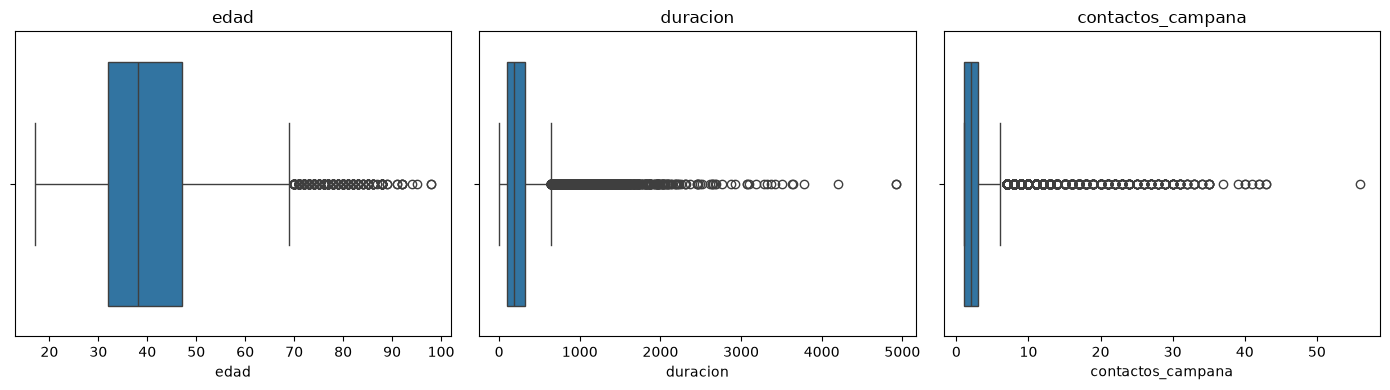

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(ejes, columnas_outliers):
    sns.boxplot(x=df_bank[col].dropna().astype(float), ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [46]:
nulos = df_bank.isnull().sum()
nulos[nulos > 0].sort_values(ascending=False)

dias_ultimo_contacto    41412
edad                     5120
fecha_contacto            248
dtype: int64

In [47]:
df_bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   edad                  37880 non-null  Int64         
 1   trabajo               43000 non-null  str           
 2   estado_civil          43000 non-null  str           
 3   educacion             43000 non-null  str           
 4   hipoteca              43000 non-null  str           
 5   prestamo              43000 non-null  str           
 6   medio_contacto        43000 non-null  str           
 7   duracion              43000 non-null  int64         
 8   contactos_campana     43000 non-null  int64         
 9   dias_ultimo_contacto  1588 non-null   Int64         
 10  contactos_previos     43000 non-null  int64         
 11  resultado_previo      43000 non-null  str           
 12  tasa_var_empleo       43000 non-null  float64       
 13  indice_precios        43000

## Resumen de la Sesión 4
- `impago` eliminada (3 casos positivos, 21 % de nulos).
- `trabajo`, `estado_civil`, `educacion`: nulos → "desconocido".
- `hipoteca` y `prestamo`: convertidas a si/no/desconocido.
- `indice_precios` y `euribor_3m`: nulos recuperados a partir de su paquete económico (groupby).
- `edad` y `fecha_contacto`: nulos conservados.
- `dias_ultimo_contacto`: 999 sustituido por nulo y creada `contactado_antes`.
- Outliers revisados con IQR y boxplots: se conservan.

## Resumen de la Sesión 4 (actualizado)
- `impago` eliminada (3 casos positivos, 21 % de nulos).
- `trabajo`, `estado_civil`, `educacion`: nulos → "desconocido".
- `hipoteca` y `prestamo`: convertidas a si/no/desconocido.
- `indice_precios` (471 nulos): recuperados a partir de su paquete económico. Cada paquete tiene un único valor.
- `euribor_3m` (9.256 nulos, 21,5 %): imputado con la mediana de su paquete. En un paquete grande (≈ 3.000 filas) el euribor varía hasta 0,88 puntos, por lo que la imputación es aproximada ahí.
- `edad` (5.120 nulos) y `fecha_contacto` (248 nulos): se conservan, no se imputan.
- `dias_ultimo_contacto`: `pdays = 999` aparece en el 96,3 % de las filas, pero **no equivale a "no contactado"**: 4.309 clientes con campaña previa fallida también lo tienen. El 999 se sustituyó por nulo (quedan 1.588 valores reales, casi todos de clientes con éxito previo).
- `contactado_antes` creada a partir de `contactos_previos > 0` (5.897 "si" y 37.103 "no"), no a partir del 999.
- Outliers revisados con IQR y boxplots: `edad` 441 (1,2 % de las filas con dato), `duracion` 3.072 (7,1 %), `contactos_campana` 2.504 (5,8 %), `ingresos` 0. Se conservan todos.
- Valores a recordar: `duracion` = 0 en 4 filas y `edad` > 90 en 10 filas, ambos conservados.